In [1]:
# Importing necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import OrderedDict

import os
data_dir = '../.data' if os.getcwd().endswith('/src') else './.data'

import logging
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    filename=f'{data_dir}/app.log'
    )

import warnings
warnings.filterwarnings('ignore')

# Downloading the data

In [2]:
import kagglehub

kagglehub.dataset_download(
    'catherinerasgaitis/mxmh-survey-results',
    path='mxmh_survey_results.csv',
    output_dir=data_dir
  )


import pandas as pd

df = pd.read_csv(f'{data_dir}/mxmh_survey_results.csv') 
df.head(3)

,Timestamp,Age,Primary streaming service,Hours per day,While working,Instrumentalist,Composer,Fav genre,Exploratory,Foreign languages,...,Frequency [R&B],Frequency [Rap],Frequency [Rock],Frequency [Video game music],Anxiety,Depression,Insomnia,OCD,Music effects,Permissions
0,8/27/2022 19:29:02,18.0,Spotify,3.0,Yes,Yes,Yes,Latin,Yes,Yes,...,Sometimes,Very frequently,Never,Sometimes,3.0,0.0,1.0,0.0,NaN,I understand.
1,8/27/2022 19:57:31,63.0,Pandora,1.5,Yes,No,No,Rock,Yes,No,...,Sometimes,Rarely,Very frequently,Rarely,7.0,2.0,2.0,1.0,NaN,I understand.
2,8/27/2022 21:28:18,18.0,Spotify,4.0,No,No,No,Video game music,No,Yes,...,Never,Rarely,Rarely,Very frequently,7.0,7.0,10.0,2.0,No effect,I understand.


# Cleaning data
### Loading, Renaming columns and Dropping minimal unnecessary columns

In [3]:
df1 = df.drop(columns=['Timestamp', 'Foreign languages', 'Permissions', 'Exploratory'])
df1.columns

Index(['Age', 'Primary streaming service', 'Hours per day', 'While working',
       'Instrumentalist', 'Composer', 'Fav genre', 'BPM',
       'Frequency [Classical]', 'Frequency [Country]', 'Frequency [EDM]',
       'Frequency [Folk]', 'Frequency [Gospel]', 'Frequency [Hip hop]',
       'Frequency [Jazz]', 'Frequency [K pop]', 'Frequency [Latin]',
       'Frequency [Lofi]', 'Frequency [Metal]', 'Frequency [Pop]',
       'Frequency [R&B]', 'Frequency [Rap]', 'Frequency [Rock]',
       'Frequency [Video game music]', 'Anxiety', 'Depression', 'Insomnia',
       'OCD', 'Music effects'],
      dtype='str')

In [4]:
# Changing column names
df1.columns = ['age', 'streaming_service', 'hours_daily', 'listen_on_work',
               'is_instrumentalist', 'is_composer',
               'fav_genre', 'bpm', 'fr_classical', 'fr_country', 'fr_edm',
               'fr_folk', 'fr_gospel', 'fr_hiphop',
               'fr_jazz', 'fr_kpop', 'fr_latin', 'fr_lofi', 'fr_metal', 'fr_pop',
               'fr_rnb', 'fr_rap', 'fr_rock', 'fr_videogame',
               'anxiety_scr', 'depression_scr', 'insomnia_scr', 'ocd_scr', 'effect']

df1.head(3)

,age,streaming_service,hours_daily,listen_on_work,is_instrumentalist,is_composer,fav_genre,bpm,fr_classical,fr_country,...,fr_pop,fr_rnb,fr_rap,fr_rock,fr_videogame,anxiety_scr,depression_scr,insomnia_scr,ocd_scr,effect
0,18.0,Spotify,3.0,Yes,Yes,Yes,Latin,156.0,Rarely,Never,...,Very frequently,Sometimes,Very frequently,Never,Sometimes,3.0,0.0,1.0,0.0,NaN
1,63.0,Pandora,1.5,Yes,No,No,Rock,119.0,Sometimes,Never,...,Sometimes,Sometimes,Rarely,Very frequently,Rarely,7.0,2.0,2.0,1.0,NaN
2,18.0,Spotify,4.0,No,No,No,Video game music,132.0,Never,Never,...,Rarely,Never,Rarely,Rarely,Very frequently,7.0,7.0,10.0,2.0,No effect


### Describing columns

In [5]:
# Numerical columns
num_cols = df1.select_dtypes(exclude=['object']).columns
stats = []
for col in num_cols:
    stats.append(OrderedDict({
        'column': col,
        'min': df1[col].min(),
        'max': df1[col].max(),
        'mean': df1[col].mean(),
        'std': df1[col].std(),
        '50%': df1[col].quantile(0.5),
        '25%': df1[col].quantile(0.25),
        '75%': df1[col].quantile(0.75),
        'IQR': df1[col].quantile(0.75) - df1[col].quantile(0.25),
        'skew': df1[col].skew(),
        'kurtosis': df1[col].kurtosis(),
        'mising_values': df1[col].isnull().sum()/df1.shape[0] * 100,
    }))

stats_df = pd.DataFrame(stats)
stats_df

,column,min,max,mean,std,50%,25%,75%,IQR,skew,kurtosis,mising_values
0,age,10.0,89.0,2.520680e+01,1.205497e+01,21.0,18.0,28.0,10.0,2.124923,4.675779,0.135870
1,hours_daily,0.0,24.0,3.572758e+00,3.028199e+00,3.0,2.0,5.0,3.0,2.532543,10.466149,0.000000
2,bpm,0.0,999999999.0,1.589948e+06,3.987261e+07,120.0,100.0,144.0,44.0,25.079872,629.000000,14.538043
3,anxiety_scr,0.0,10.0,5.837636e+00,2.793054e+00,6.0,4.0,8.0,4.0,-0.421350,-0.765791,0.000000
4,depression_scr,0.0,10.0,4.796196e+00,3.028870e+00,5.0,2.0,7.0,5.0,-0.048449,-1.145947,0.000000
5,insomnia_scr,0.0,10.0,3.738451e+00,3.088689e+00,3.0,1.0,6.0,5.0,0.416455,-1.021272,0.000000
6,ocd_scr,0.0,10.0,2.637228e+00,2.842017e+00,2.0,0.0,5.0,5.0,0.954291,-0.127324,0.000000


In [6]:
# Categorical columns
cat_cols = df1.select_dtypes(include=['object']).columns
stats = []
for col in cat_cols:
    stats.append(OrderedDict({
        'column': col,
        'unique_values': df1[col].nunique(),
        'top_value': df1[col].mode()[0],
        'top_value_percentage': df1[col].value_counts(normalize=True).iloc[0] * 100,
        'missing_values_percentage': df1[col].isnull().sum()/df1.shape[0] * 100,
        'unique_values_list': df1[col].unique()
    }))

pd.set_option('display.max_colwidth', None)
stats_df = pd.DataFrame(stats).sort_values(by='top_value_percentage', ascending=False)
stats_df

,column,unique_values,top_value,top_value_percentage,missing_values_percentage,unique_values_list
3,is_composer,2,No,82.857143,0.135870,"[Yes, No, nan]"
1,listen_on_work,2,Yes,78.990450,0.407609,"[Yes, No, nan]"
21,effect,3,Improve,74.450549,1.086957,"[nan, No effect, Improve, Worsen]"
9,fr_gospel,4,Never,72.690217,0.000000,"[Never, Sometimes, Rarely, Very frequently]"
2,is_instrumentalist,2,No,67.896175,0.543478,"[Yes, No, nan]"
0,streaming_service,6,Spotify,62.312925,0.135870,"[Spotify, Pandora, YouTube Music, I do not use a streaming service., Apple Music, Other streaming service, nan]"
13,fr_latin,4,Never,60.190217,0.000000,"[Very frequently, Sometimes, Never, Rarely]"
12,fr_kpop,4,Never,56.521739,0.000000,"[Very frequently, Rarely, Sometimes, Never]"
6,fr_country,4,Never,46.603261,0.000000,"[Never, Sometimes, Very frequently, Rarely]"
19,fr_rock,4,Very frequently,44.836957,0.000000,"[Never, Very frequently, Rarely, Sometimes]"


### Description conclusions
* Columns (hours_daily & bpm) have un-reasonable maximum values (outliers), which must be the cause of high kurtosis and skewness values. 
* bpm also has 14.5% of missing values, which requires fix, as this value may show some corelations to mental health improvement.
* For categorical missing values we can imputate with mode, as they are all around and lower than 1%.
* fr_* columns have 4 unique values, with no missing values.
* There 3 columns with (Yes/No) answer. (is_composer, listen_on_work, is_instrumentalist)
* Column streaming_service shows 6 unique_values with one for missing values and "I do not use streaming service" value. That is 4 streaming service.
* fav_genre column has 16 uniques values, with 25% being Rock.

### Removing outliers using IQR

<Axes: >

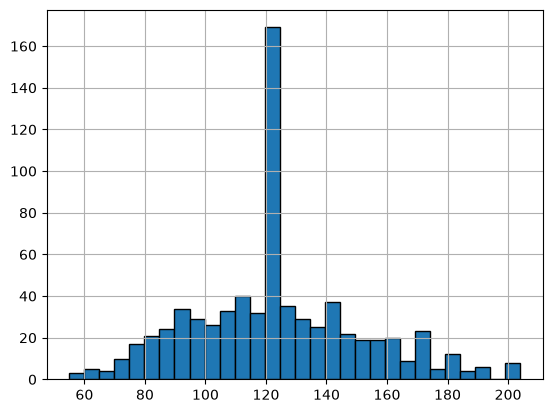

In [7]:
# Dealing with bpm column
total_rows = df1.shape[0]

# Filling missing values with median
df1['bpm'] = df1['bpm'].fillna(df1['bpm'].median())

# Removing outliers by keeping only values within the 1st and 99th percentiles
df1 = df1[(df1['bpm'] < df1['bpm'].quantile(0.99)) & (df1['bpm'] > df1['bpm'].quantile(0.01))]

df1.bpm.hist(bins=30, edgecolor='black')


<Axes: >

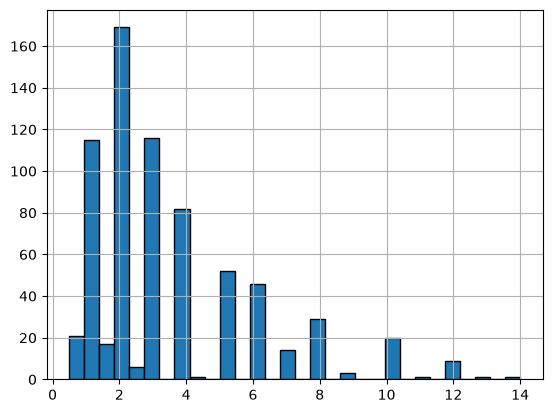

In [8]:
# Dealing with hours_daily column
# Filling missing values with median
df1['hours_daily'] = df1['hours_daily'].fillna(df1['hours_daily'].median())

# Removing outliers by keeping only values within the 1st and 99th percentiles
df1 = df1[(df1['hours_daily'] < df1['hours_daily'].quantile(0.99)) & (df1['hours_daily'] > df1['hours_daily'].quantile(0.01))]

df1['hours_daily'].hist(bins=30, edgecolor='black')

In [9]:
# Row drop stats
print(f"Total rows before dropping: {total_rows}")
print(f"Rows dropped due to outliers: {total_rows - df1.shape[0]}")

Total rows before dropping: 736
Rows dropped due to outliers: 33


### Applying median imputations on numerical missing values

In [10]:
columns_with_missing_values = df1.select_dtypes(include=['float64', 'int64']).columns

for col in columns_with_missing_values:
    df1[col] = df1[col].fillna(df1[col].median())

### Applying mode imputations on categorical missing values

In [11]:
columns_with_missing_values = df1.select_dtypes(include=['object']).columns

for col in columns_with_missing_values:
    df1[col] = df1[col].fillna(df1[col].mode()[0])


# Beauty fixes

### Primary Streaming service fix


In [12]:
df1.streaming_service = df1.streaming_service.replace(
    {'I do not use a streaming service.': 'Other',
     'Other streaming service': 'Other'}
)

### Favorite Genre

In [13]:
df1.fav_genre = df1.fav_genre.replace (
    {'Video game music': 'VideoGame',
     'Hip hop': 'HipHop',
     'K pop': 'KPop'
    }
)

### Music Effect

In [14]:
# Filling here is unnecessary, but keeping it for future changes.
df1.effect = df1.effect.fillna('No effect')

### Setting frequencies
If na set to Never

In [15]:
# fr_* columns are filled with 'Never' for missing values
columns_with_missing_values = ['fr_classical', 'fr_country', 'fr_edm', 'fr_folk', 'fr_gospel',
                               'fr_hiphop', 'fr_jazz', 'fr_kpop', 'fr_latin', 'fr_lofi', 'fr_metal', 'fr_pop', 'fr_rnb', 'fr_rap', 'fr_rock', 'fr_videogame']

# Filling here is unnecessary, but keeping it for future changes.
for col in columns_with_missing_values:
    df1[col] = df1[col].fillna('Never')

### Saving cleaned data to file

In [16]:
df1.to_csv(f'{data_dir}/mxmh_survey_results_clean.csv', index=False)

# Asking questions and analysis

### Effect distribution

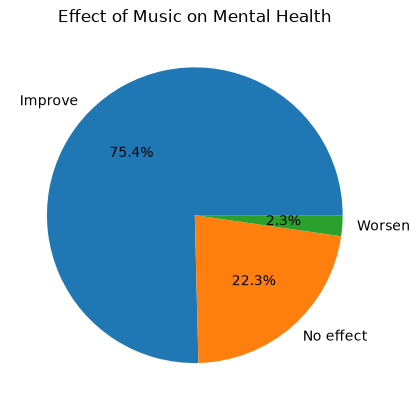

In [17]:
# Effect distribution
effect_dist = \
df1.effect.value_counts(normalize=True) \
   .plot(
      kind='pie',
      title='Effect of Music on Mental Health',
      autopct='%1.1f%%')


* **Effects of reported improvement is at 75.4%, which can be considered high enough.**
****

### Does effect change by disorder?

<Axes: title={'center': 'Effect of Music on Mental Health for Different Disorders'}, xlabel='effect'>

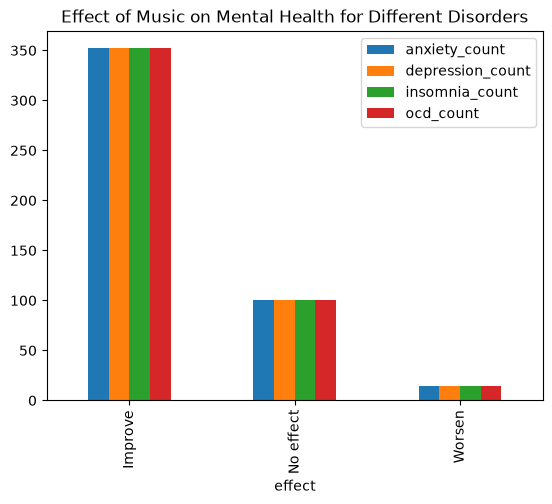

In [18]:
# Effect distribution among different mental disorders
# Considering disorder to be valid if the score >= 7 (arbitrary threshold)
threshold = 7
df_filtered = df1[(df1.anxiety_scr >= threshold) | (df1.depression_scr >= threshold) | (df1.insomnia_scr >= threshold) | (df1.ocd_scr >= threshold)]
df_filtered.groupby('effect').agg(anxiety_count=('anxiety_scr', 'count'),
                                 depression_count=('depression_scr', 'count'),
                                 insomnia_count=('insomnia_scr', 'count'),
                                 ocd_count=('ocd_scr', 'count')) \
.plot(kind='bar', title='Effect of Music on Mental Health for Different Disorders')

* **Effects are independent of mental health disorders.**
****

### Does "Effect" changes by genres?

* There are two different ways to select genres here, one is using fav_genre column or select it by fr_* columns.
* What user has listened to matters more than what they like to listen, because they can choose to not listen to their fav_genre.

,Improve,No effect,Worsen,total_listeners
fr_classical,73.529412,24.509804,1.960784,102
fr_country,81.250000,16.666667,2.083333,48
fr_edm,76.470588,21.176471,2.352941,85
fr_folk,76.000000,22.666667,1.333333,75
fr_gospel,100.000000,0.000000,0.000000,12
fr_hiphop,75.000000,21.666667,3.333333,120
fr_jazz,78.000000,20.000000,2.000000,50
fr_kpop,82.432432,17.567568,0.000000,74
fr_latin,76.666667,16.666667,6.666667,30
fr_lofi,78.048780,20.731707,1.219512,82


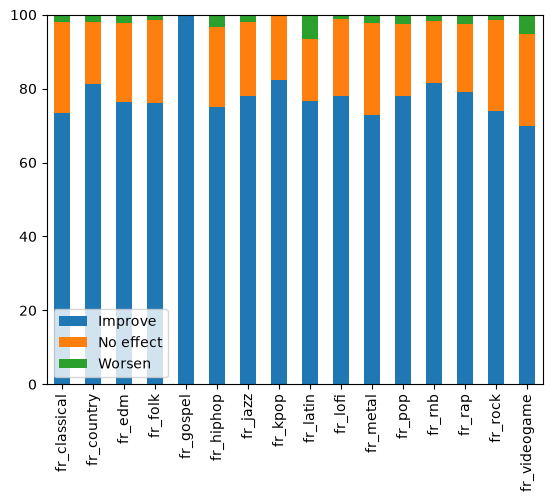

In [19]:
# fr_* columns distribution to should be counted only if column has values ['Often', 'Always']
# Users listening to genres with high frequency, should increase count of listener to that genre.

genre_df = pd.DataFrame()
genre_df.index = df1.columns[df1.columns.str.startswith('fr_')]

for effect in df1['effect'].unique():
    genre_df[effect] = [df1[(df1['effect'] == effect) & (df1[idx] == 'Very frequently')][idx].count() for idx in genre_df.index]    

# normalizing the df by index
genre_df = genre_df.div(genre_df.sum(axis=1), axis=0) * 100

genre_df.plot(kind='bar', stacked=True)

genre_df['total_listeners'] = [df1[df1[idx] == 'Very frequently'][idx].count() for idx in genre_df.index]
genre_df

* **Except gospel listener, all show around 75 - 80% Improvement.**
* **Gospel listener report 100% improvement, but their are only 12 listeners in total.**
****

### Does "Effect" differs across age group?

Thing to note:
* age distribution by itself isnt equal so, directly counting effects will result in uneven distribution.
* Can stack different age groups between (effect, worsen, no effect). And look at percent of effect.

effect,Improve,No effect,Worsen,total
age_group,,,,
"(0, 18]",0.800885,0.172566,0.026549,226
"(18, 35]",0.728205,0.251282,0.020513,390
"(35, 50]",0.695652,0.260870,0.043478,46
"(50, 60]",0.750000,0.250000,0.000000,24
"(60, 70]",0.857143,0.142857,0.000000,14
"(70, 80]",1.000000,0.000000,0.000000,3


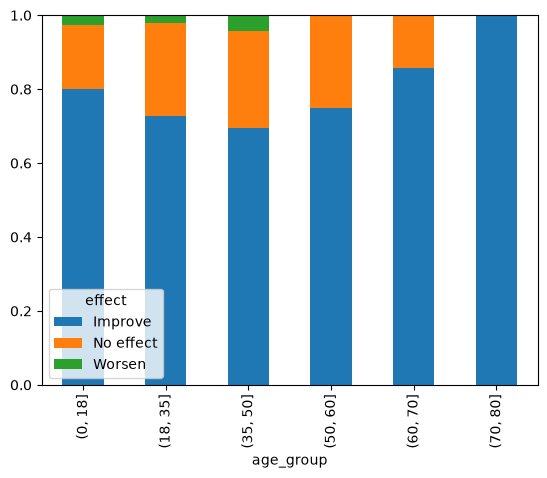

In [20]:
age_df = df1.copy()
bins = [0, 18, 35, 50, 60, 70, 80, 90, 100]
age_df['age_group'] = pd.cut(df1['age'], bins=bins)
totals = df1.groupby(pd.cut(df1['age'], bins=bins))['effect'].count()

age_df = pd.crosstab(age_df['age_group'], age_df['effect'], normalize='index')
age_df.plot(kind='bar', stacked=True)

age_df['total'] = totals
age_df


* **Age group 50 & above do not have "Worsen" effect.**
* **And age group 70 & above only show Improvement, but there are only 3 reported listeners.**
* **Most of the reported listeners are from age group of 0-34.**
* **People between 0 & 49 show improvement are within 75% - 80%**
****

### Does effect correlates to BPM of music

* Divide BPM into groups of 20 till 120 as perceived differences here are greater, after that let's do 50.

effect,Improve,No effect,Worsen,total
bpm_group,,,,
"(50, 60]",0.800000,0.000000,0.200000,5
"(60, 70]",0.700000,0.300000,0.000000,10
"(70, 80]",0.742857,0.228571,0.028571,35
"(80, 90]",0.829268,0.170732,0.000000,41
"(90, 100]",0.741935,0.225806,0.032258,62
"(100, 110]",0.828125,0.156250,0.015625,64
"(110, 120]",0.710000,0.270000,0.020000,200
"(120, 140]",0.725191,0.236641,0.038168,131
"(140, 160]",0.807692,0.179487,0.012821,78


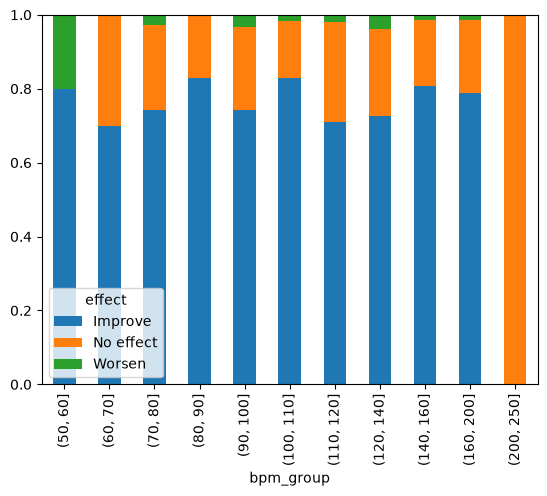

In [21]:
bpm_df = df1.copy()
bins = [30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 140, 160, 200, 250, 300]

bpm_df['bpm_group'] = pd.cut(df1['bpm'], bins=bins)
counts = df1.groupby(pd.cut(df1['bpm'], bins=bins))['effect'].count()

bpm_df = pd.crosstab(bpm_df['bpm_group'], bpm_df['effect'], normalize='index')
bpm_df.plot(kind='bar', stacked=True)
bpm_df['total'] = counts
bpm_df

* **There is only reported listener from group 200 - 250.**
* **And Reported listener for group 50 - 69 only count to 15.**
* **People listening to musics of BPM 50 to 199 are likely to see improvement 75% of the time.**
****